#### MA124 Maths by Computer
# Project: Modelling in Epidemiology

#### Background
Epidemiological models are increasingly used during infectious disease outbreaks to make outbreak projections and to guide control interventions. This project involves developing simple computational models of outbreaks and using them to predict the effects of different interventions. It also involves using stochastic epidemiological models (models that include randomness) to predict the risk that early cases at the beginning of an outbreak lead on to a major epidemic (with a large number of cases) as opposed to fade out as a minor outbreak (with a small number of cases). 

If more details are required about the background epidemiological modelling theory, please rewatch the Epidemiology Lecture, available on the MA124 moodle page.

#### Structure of project
There are six tasks in the document below, tasks A1-A5 and then task B1. Your group should do all six of these tasks. Tasks A1-A5 are worth approximately 60% of the credit for this submission and task B1 is worth the rest (approximately 40%).

#### Notes about submission
Read through the document **MA124 Maths by Computer Tutor Group Projects Information for Students.pdf** on the MA124 Moodle page.

Before submitting see the notes at the end of this document.

#### Allowed libraries for this project 
Python libraries/modules should be used as required to complete the tasks in this project, with no restrictions.

## Section A (worth approximately 60% of the marks)

## The Deterministic SIR model

In the Epidemiology lecture, you met the deterministic SIR model given by a system of three ODEs.

This part of the assignment builds on the "Epidemiology I code" notebook, which provides code for numerically solving the SIR model in Python. We are interested in extensions to the SIR model as presented there: specifically, extensions involving public health measures such as vaccination and social distancing.

Note: You are expected to add code and markdown cells to this document as appropriate to provide your responses to the tasks. However, throughout this assignment, please do use the deterministic and stochastic SIR model codes from the Epidemiology I and Epidemiology II code notebooks as required (i.e., you are supposed to copy that code across and adapt it, rather than start coding from scratch).

---

## Task A1. Baseline case (worth approximately 12% of the marks)
**Assignment:** Using Python, solve the deterministic SIR model numerically and examine the solution for one set of parameter values and one initial condition. Then, adapt the code to rerun the analysis multiple times for different infection rates.

Details: 
- Use the following parameter values for the baseline case (where, throughout this Assignment, time is measured in days): $\beta = 2 \times 10^{-5}$, $\mu = 0.1$, $N = 10^{4}$.
- Initiate the numerical solution starting with 3 infected individuals, with the remainder of the population susceptible.
- Produce two plots: a time-series showing $S(t)$, $I(t)$ and $R(t)$ and a phase plane (in the $(S,I)$ plane).
- On both plots, indicate the point on the trajectory where $I$ reaches its maximum as black circles, and print this maximum value (when you print the value, round this value to the largest integer that is less than this value).
- Now repeat this analysis a large number of times for different values of $\beta$ (without generating a figure each time; so as to not generate a huge number of figures!) Plot the maximum value of $I$ as a function of $\beta$, choosing an appropriate range of values of $\beta$ (and sufficiently many values) to be able to see the dependence clearly.

Hint: You might like to Google the appropriate NumPy function that finds the maximum value in a vector. For the last part, use a FOR loop rather than changing the value of $\beta$ manually.

Once you have completed this, you might like to help your team member who is doing Task A4 below!

*Insert code and markdown cells below, as appropriate, in which to provide your response to this task.*

---

### Task A1: Baseline SIR Model Analysis

In this task, we investigate the behaviour of the deterministic SIR (Susceptible–Infected–Removed) model using numerical methods in Python. We begin by simulating the spread of an infection for a fixed set of parameter values and initial conditions, allowing us to visualise how the numbers of susceptible, infected, and removed individuals evolve over time.

We then analyse key features of the solution, including identifying and marking the peak number of infected individuals. To better understand how the infection dynamics depend on model parameters, we extend the analysis by repeating the simulation for a range of infection rates. This allows us to explore how changes in the transmission rate influence the maximum outbreak size, providing insight into the sensitivity of the epidemic to this parameter.

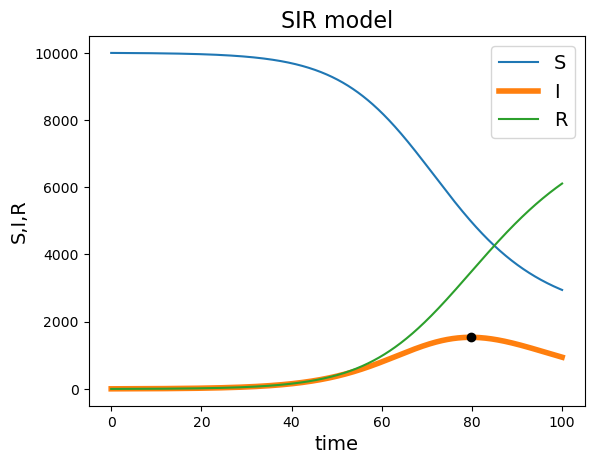

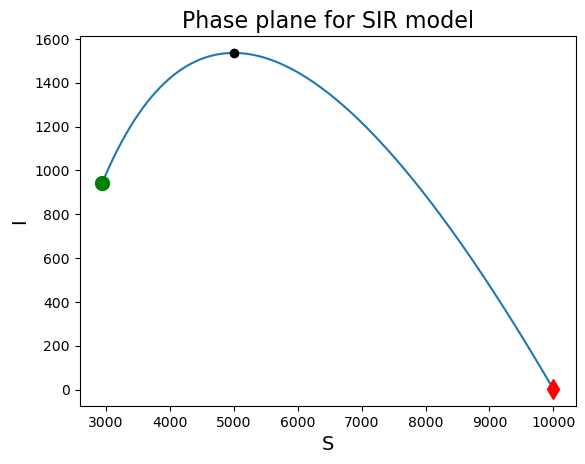

Maximum value of I: 1535


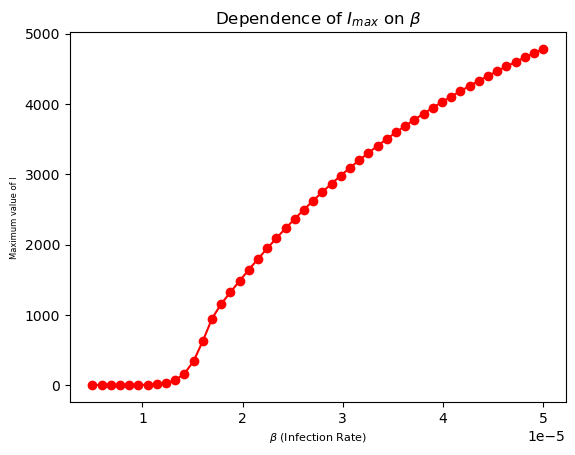

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

#Let the function take four arguments
def SIR(y, t, beta, mu):
    S, I, R=y

    # Define total population as sum of each of the container variables
    N = S + I + R
    Sdot = -beta * S * I
    Idot = beta * S * I - mu * I
    Rdot = mu * I
    
    return Sdot, Idot, Rdot

#Set up time grid for the solution
tf = 100
Nsteps = 1000
t = np.linspace(0, tf, Nsteps+1)

#Now define them and set initial conditions
beta = 2*(10**-5)
mu = 0.1
S0 = 10**4 - 3
I0 = 3
R0 = 0
y0 = np.array([S0, I0, R0])

#Initiate the numerical solution
y_sol = odeint(SIR, y0, t, args=(beta,mu))

S = y_sol[:,0]
I = y_sol[:,1]
R = y_sol[:,2]

#Find the max value of I using argmax function
index_of_max = np.argmax(I)
max_I_value = I[index_of_max]

#Plot S,I,R graph
plt.plot(t, S, label = "S")
plt.plot(t, I, lw = 4, label = "I")
plt.plot(t, R, label = "R")

plt.xlabel("time", fontsize = 14)
plt.ylabel("S,I,R", fontsize = 14)
plt.title("SIR model", fontsize = 16)
plt.legend(fontsize = 14)
plt.plot(t[index_of_max], max_I_value, 'ko', label='Max I') #labeling I
plt
plt.show()

#Plot the phase plane graph
plt.plot(S, I)

plt.xlabel("S", fontsize = 14)
plt.ylabel("I", fontsize = 14)
plt.title("Phase plane for SIR model", fontsize = 16)

plt.plot(S[0], I[0], 'rd', markersize = 10)
plt.plot(S[-1], I[-1], 'go', markersize = 10)
plt.plot(S[index_of_max], max_I_value, 'ko', label='Max I')#labeling max I value
plt.show()

print(f"Maximum value of I: {int(np.floor(max_I_value))}")#print max_I value

#Create an empty list
beta_values = np.linspace(5e-6, 5e-5, 50)
max_I_list = []

#Use for loop to solve and record the value
for b in beta_values:
    sol_loop = odeint(SIR, y0, t, args = (b, mu))
    current_I_max = np.max(sol_loop[:, 1])
    max_I_list.append(current_I_max)

#Plot graph of Imax against beta
plt.plot(beta_values, max_I_list, 'r-o')
plt.xlabel(r'$\beta$ (Infection Rate)',fontsize = 8)
plt.ylabel('Maximum value of I',fontsize = 6)
plt.title(r'Dependence of $I_{max}$ on $\beta$')
plt.show()

## Task A2. The effect of vaccination (worth approximately 12% of the marks)
**Assignment:** Using Python, solve the deterministic SIR model numerically for different numbers of individuals vaccinated. 

Details:
- Use the following parameter values for the baseline case: $\beta = 2 \times 10^{-5}$, $\mu = 0.1$, $N = 10^{4}$.
- Assume that each simulation starts with 5 infected individuals (with the remainder of the population susceptible, other than those who have been vaccinated).
- Assume that vaccination involves simply withdrawing susceptible individuals from the population (to a new $V$ compartment, which is different to the removed ($R$) compartment) instantaneously at the start of the numerical simulation, and that vaccination is perfectly effective.
- Make a plot of the total number of individuals who are either infected or removed (i.e., $I+R$) after 500 days as a function of the number of vaccinated hosts. Hint: This will require running the SIR model multiple times (once for each value of the number of vaccinated individuals, $V$) using a FOR loop.
- Add markers to the plot corresponding to the (strictly positive) numerical solution of the final size equation (explained in the Lecture and below), in which $N$ is simply reduced by $V$, for values of i) $V = 1000$; ii) $V = 2000$; iii) $V = 3000$.
- Include a derivation of the final size equation in your answer to this task.

- Hint: Recall that the final size equation is $x = N - N \rm{exp} \left( -\frac{\beta x}{\mu} \right)$ in a scenario without vaccination (vaccination then corresponds to reducing the value of $N$). You will have to look up an appropriate Python function to solve this equation numerically. To find the strictly positive solution (rather than the solution $x = 0$) numerically, a sufficiently large "initial guess" may need to be input to the relevant Python function.

*Insert code and markdown cells below, as appropriate, in which to provide your response to this task.*

---

### Task A2: The Effect of Vaccination

In this task, we extend the deterministic SIR model to investigate the impact of vaccination on the spread of an infection. Vaccination is incorporated by removing a specified number of individuals from the susceptible population at the start of the simulation, assuming that vaccination is instantaneous and perfectly effective.

We numerically solve the SIR model for a range of vaccination levels, each time tracking the total number of individuals who have been infected or removed by the end of the simulation period. By plotting this quantity against the number of vaccinated individuals, we can observe how increasing vaccination coverage influences the overall epidemic size.

To complement the numerical results, we also compute solutions to the final size equation for selected vaccination levels. These values are added to the plot as markers, allowing for a direct comparison between the numerical simulations and the theoretical predictions. A derivation of the final size equation is included to provide further insight into the underlying model behaviour.

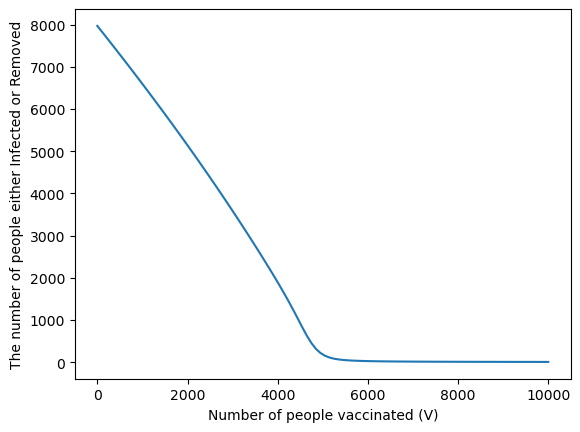

100


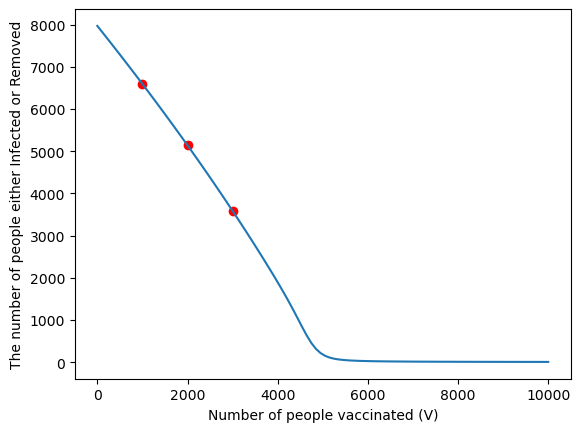

In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.integrate import odeint 

# Define SIR ODE equations 
def SIR(y, t):
    S, I, R = y

    # Initialise state variables
    beta = 2*(10**-5)
    mu = 0.1

    # Total population
    N = S + I + R 

    # Differential equations
    Sdot = -beta * S * I
    Idot = beta * S * I - mu * I
    Rdot = mu * I
    
    return Sdot, Idot, Rdot

# Set initial conditions
N = 10**4
I0 = 5
R0 = 0 

# Range of vaccinated individuals set up (upto 10000 in increments of 100)
V_values = np.linspace(0, 10000, 100)        
tf = 500
Nsteps = 1000
t = np.linspace(0, tf, Nsteps+1)

# Array to store value of I + R at end of pandemic
I_or_R = []

# Iterate through the vaccination levels
for V in V_values:

    # Adjust initial susceptible population aaccounting for vaccination
    S0 = N - V - I0
    y0 = np.array([S0, I0, R0])

    # Numerically solve the system of equations
    y_sol = odeint(SIR, y0, t)

    # Extract the solutions
    S = y_sol[:,0]
    I = y_sol[:,1]
    R = y_sol[:,2]

    # Store final epidemic size
    I_or_R.append(I[-1]+R[-1])

# Plot final epidemic size against vaccination level
plt.plot(V_values, I_or_R)
plt.xlabel("Number of people vaccinated (V)")
plt.ylabel("The number of people either Infected or Removed")   
plt.show()
print(len(I_or_R))

# importing function fsolve to find root for final solve equation
from scipy.optimize import fsolve 

# define parameters
beta = 2*(10**-5)
mu = 0.1

# Define the final size equation:
# x = N_without_V * (1 - exp(-(beta/mu)*x))
# Rearranged to f(x) = 0 for root finding
def final_size(x, N_without_V):
    return (x - ((N_without_V) - (N_without_V)*np.exp(-(beta*x)/mu)))
   
# Vaccination values for which we compute analytical final size
V_markers = [1000,2000,3000]

# Initialise array to store final size equation solutions
Final_Size_Results = []

for V in V_markers:
    
    # Effective population after vaccination
    N_without_V = N - V
    
    # Initial guess for root (must be non-zero to avoid trivial solution)
    x0 = N_without_V
    
    # Solve final size equation numerically
    root = fsolve(final_size, x0, args=(N_without_V,))
    
    # Store strictly positive solution
    Final_Size_Results.append(root[0])

# Plot numerical simulation results again
plt.plot(V_values, I_or_R)
plt.xlabel("Number of people vaccinated (V)")
plt.ylabel("The number of people either Infected or Removed")   

# Add markers for each of the solutions
plt.scatter(V_markers, Final_Size_Results, color = 'red')
plt.show()

## Task A3. The effect of social distancing (worth approximately 12% of the marks)

The introduction and/or removal of social distancing can be modelled by varying the infection rate parameter, $\beta$. In this exercise, we will use the following time-dependent infection rate parameter:

$$
\beta(t)  = 2 \times 10^{-7} \text{  whenever  } t < T, \\
\beta(t)  = 1.5 \times 10^{-7} \text{  whenever  } T \le t \le T + 30, \\
\beta(t)  = 2 \times 10^{-7} \text{  whenever  } t > T + 30. \\
$$

**Assignment:** Using Python, run the deterministic SIR model for the social distancing strategy described above.

Details:
- For this task, use the values $\mu = 0.1$, $N = 10^{6}$, and assume that the initial values of $(S,I,R)$ are $(N-5,5,0)$.
- Run the SIR model, adapted according to the time-dependent value of $\beta$ described above, for a value of $T = 30$ days. Plot a time-series showing $S(t)$, $I(t)$ and $R(t)$.
- Consider a scenario in which $T$ is not necessarily 30 days, and can instead take a fixed integer value between 1 and 200 days. Write a FOR loop to identify the value of $T$ that minimises the maximum value of $I$ in the model simulation. Plot the maximum value of $I$ as a function of $T$, and print the value of $T$ that "flattens the curve" most.

*Insert code and markdown cells below, as appropriate, in which to provide your response to this task.*

---

### Task A3: The Effect of Social Distancing

In this task, we investigate how social distancing influences the spread of an infection within the deterministic SIR model. Social distancing is incorporated by allowing the infection rate parameter to vary over time, representing periods where transmission is reduced.

We begin by simulating the SIR model with a time-dependent infection rate over a fixed duration, and produce time-series plots of the susceptible, infected, and removed populations. This allows us to observe how introducing and lifting social distancing measures affects the progression of the epidemic.

We then extend the analysis by considering different durations of social distancing. By running the model multiple times for varying lengths of intervention, we identify the duration that minimises the peak number of infected individuals. Finally, we plot how the maximum number of infected individuals depends on the duration of social distancing, providing insight into how such measures can be used to "flatten the curve".

In [3]:
#import libraries

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint 

T=30

#define time dependent function for parameter beta

def beta(t):
    if t<T or t>T+30:
        return 2 * 10**-7
    if T<=t<=T+30:
        return 1.5 * 10**-7
        
#follow method for how to solve SIR model DEs outlined in Epidemiology 1 Code

def SIR(y, t):
    S, I, R = y

    mu = 0.1
    
    N = S + I + R
    Sdot = -beta(t) * S * I
    Idot = beta(t) * S * I - mu * I
    Rdot = mu * I
    
    return Sdot, Idot, Rdot

#set final value of t as 300 instead of 100 as used in the original code as the model now takes place over a larger time
#period so tf=100 would not have shown all the changes in S, I and R over the course of the epidemic

tf = 300
Nsteps = 1000
t = np.linspace(0, tf, Nsteps+1)

S0 = 10**6 - 5
I0 = 5
R0 = 0
y0 = np.array([S0, I0, R0])

y_sol = odeint(SIR, y0, t)

S = y_sol[:,0]
I = y_sol[:,1]
R = y_sol[:,2]

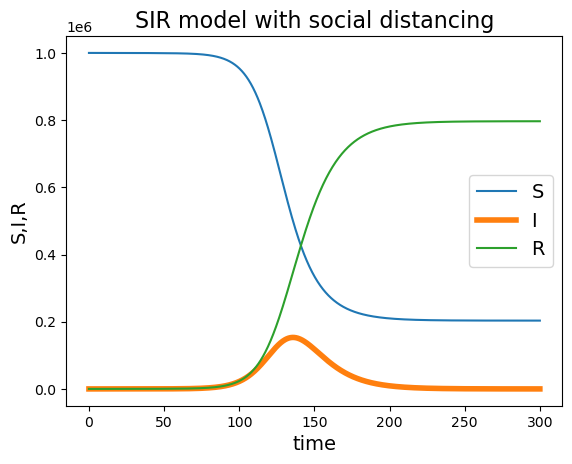

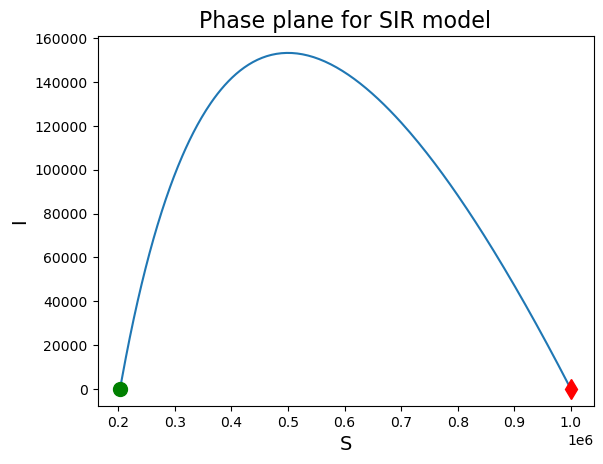

At the end of the simulation, the final values of S, I, and R are (rounded):
S(t=tf) = 203323
I(t=tf) = 25
R(t=tf) = 796652


In [4]:
#follow method for plotting SIR model and phase plane outlined in Epidemiology 1 Code

plt.plot(t, S, label = "S")
plt.plot(t, I, lw = 4, label = "I")
plt.plot(t, R, label = "R")

plt.xlabel("time", fontsize = 14)
plt.ylabel("S,I,R", fontsize = 14)
plt.title("SIR model with social distancing", fontsize = 16)
plt.legend(fontsize = 14)
plt.show()        

plt.plot(S, I)

plt.xlabel("S", fontsize = 14)
plt.ylabel("I", fontsize = 14)
plt.title("Phase plane for SIR model", fontsize = 16)

plt.plot(S[0], I[0], 'rd', markersize = 10)
plt.plot(S[-1], I[-1], 'go', markersize = 10)
plt.show()


print("At the end of the simulation, the final values of S, I, and R are (rounded):")
print("S(t=tf) =", round(S[-1]))
print("I(t=tf) =", round(I[-1]))
print("R(t=tf) =", round(R[-1]))

In [5]:
#define function to find the 'peak' of I for each value of T using code from previous part 

def maxI(T):
    def beta(t):
        if t<T or t>T+30:
            return 2 * 10**-7
        if T<=t<=T+30:
            return 1.5 * 10**-7

    def SIR(y, t):
        S, I, R = y

        mu = 0.1
    
        N = S + I + R
        Sdot = -beta(t) * S * I
        Idot = beta(t) * S * I - mu * I
        Rdot = mu * I
    
        return Sdot, Idot, Rdot
            
    tf = 300
    Nsteps = 1000
    t = np.linspace(0, tf, Nsteps+1)

    S0 = 10**6 - 5
    I0 = 5
    R0 = 0
    y0 = np.array([S0, I0, R0])

    y_sol = odeint(SIR, y0, t)

    I = y_sol[:,1]
    return max(I)

The value which 'flattens the curve' of I the most is T = 99 , giving a maximum of 90856.40755813295


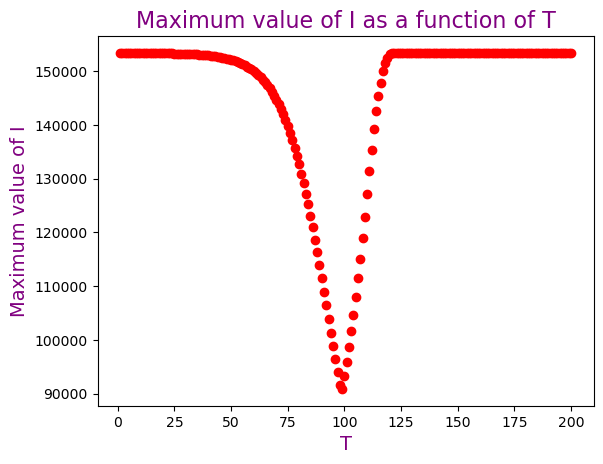

In [6]:
#plot results and print value of T which gives lowest max value of I

values = []
for T in range (1,201):
    values.append(maxI(T))

for i in range (1,201):
    plt.plot(i,maxI(i),'r-o')
    plt.xlabel('T', fontsize = 14, color = 'purple')
    plt.ylabel('Maximum value of I', fontsize = 14, color = 'purple')
    plt.title('Maximum value of I as a function of T', fontsize = 16, color = 'purple')
A = np.argmin(values)
minT = A+1

print("The value which 'flattens the curve' of I the most is T =",minT,", giving a maximum of",maxI(minT))

## The Stochastic SIR model


This part of the assignment builds on the "Epidemiology II code" notebook, which provides code for running one simulation of the stochastic SIR model in Python. We are interested in running simulations to compare the dynamics of the deterministic SIR model and stochastic SIR model, and to estimate the probability of a major outbreak when a single infected individual enters an entirely susceptible population using the stochastic SIR model.

---

## Task A4. Comparison between the stochastic and deterministic SIR models (worth approximately 12% of the marks)

**Assignment:** The end goal of this task is to run 100 simulations of the stochastic SIR model, generate a plot showing the mean value of $I(t)$ (averaged across all of the simulations) versus $t$, and then compare this output to the analogous output from the deterministic SIR model.

Details: 
- We will use the following parameter values for the baseline case (where, throughout this assignment, time is measured in days): $\beta = 3 \times 10^{-4}$, $\mu = 0.1$, $N = 10^{3}$.
- In each simulation, there will be 10 individuals infected initially (with the rest of the population susceptible).
- The most challenging part of this task is that, in each simulation, events will occur at different times. As a result, we have to write code that, for each simulation, extracts the value of $I(t)$ at a set of pre-defined values of $t$. One way to do this is to set up a vector at the beginning of the simulation containing 201 blank entries (corresponding to $t = 0, 0.5, 1, 1.5, ..., 100$), and then populate the relevant entries after each event (i.e. put the value of $I$ before the current event in all entries corresponding to times between the last event time and the current one). This vector can then be averaged across all simulations.
- The code in the Python notebook entitled "Epidemiology_Part_A4_with_Errors" is a first attempt at writing such code (i.e. code that outputs a vector $I_{vals}$ with entries recording the values of $I$ at $t = 0, 0.5, 1, 1.5, ..., 100$) for a single simulation of the stochastic SIR model, but it contains three mistakes. Correct this code (and then copy the resulting code into your answer to this task in this notebook).
- Now that you have corrected the code described above, run 100 simulations of the stochastic SIR model and plot the average values of the vector $I_{vals}$, plotted at $t = 0, 0.5, 1, 1.5, ..., 100$.
- Finally, on the same axes, plot the analogous numerical solution of the determinstic SIR model. The team member who completed Task A1 (above) should be able to help you with this.

*Insert code and markdown cells below, as appropriate, in which to provide your response to this task.*

---

### Task A4: Comparison Between Stochastic and Deterministic SIR Models

In this task, we compare the behaviour of the stochastic and deterministic SIR models. The stochastic model accounts for randomness in the timing of infection and recovery events, while the deterministic model provides a smooth, average description of the epidemic dynamics.

We begin by correcting a provided implementation of the stochastic SIR model so that it correctly records the number of infected individuals at a fixed set of time points. Using this corrected code, we run multiple simulations of the stochastic model and compute the average number of infected individuals over time.

Finally, we compare these averaged stochastic results with the corresponding solution of the deterministic SIR model by plotting both on the same axes. This comparison highlights the differences between individual realisations of an epidemic and the average behaviour predicted by the deterministic approach. It also demonstrates the effectiveness of averaging a stochastic model over many runs as it closesly matches analytical output from the deterministic model while accounting for randomness of infection spread.

## Corrected code

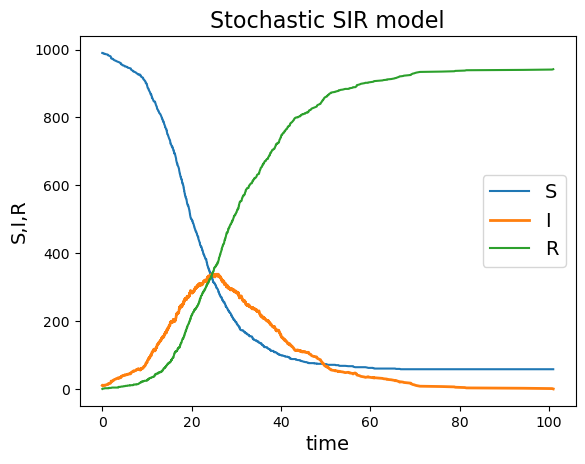

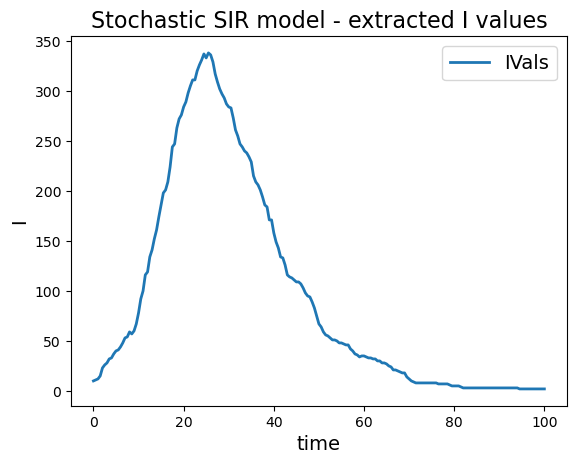

In [7]:
# import libraries
import numpy as np  
import matplotlib.pyplot as plt


# Parameter values
beta = 3.0*10**-4
mu = 0.1

# Set up arrays to record event times, and values of S, I and R after after each event
SVec = np.array([])
IVec = np.array([])
RVec = np.array([])
tVec = np.array([])

# Set up an array to record pre-determined times and values of I at those times
tVals = np.array([i*0.5 for i in range(201)])
IVals = np.array([0 for i in range(201)])

# Set initial conditions and the initial time
S = 10**3 - 10
I = 10
R = 0
t = 0

IVals[0] = I

# Record initial conditions in the S, I, R and t arrays
SVec = np.append(SVec, S)
IVec = np.append(IVec, I)
RVec = np.append(RVec, R)
tVec = np.append(tVec, t)

# While the outbreak is ongoing (I > 0), generate events
  
while I > 0:
    
    previous_time = t

    # Random sampling used for random event simulation
    r1 = np.random.uniform(0, 1, 1)

    # Using Gillespie direct method so exponential distribution assumption there calculate rate parameter
    totalRate = beta*I*S + mu*I

    # Using exponential distribution, calculate time of next event
    t = t - (1/totalRate)*np.log(r1)
    
    new_time = t
    
    for i in range(201):
        if previous_time <= tVals[i] < new_time:
            IVals[i] = I
    
    r2 = np.random.uniform(0, 1, 1)
    
    if r2 < (beta*I*S)/totalRate:
        # Next event is infection
        S = S - 1
        I = I + 1
    else:
        I = I - 1
        R = R + 1

    # Update S,I,R,t arrays
    SVec = np.append(SVec, S)
    IVec = np.append(IVec, I)
    RVec = np.append(RVec, R)
    tVec = np.append(tVec, t)

# plot the time evolution of the S, I, R
plt.plot(tVec, SVec, label = "S")
plt.plot(tVec, IVec, lw = 2, label = "I")
plt.plot(tVec, RVec, label = "R")

# labels etc
plt.xlabel("time", fontsize = 14)
plt.ylabel("S,I,R", fontsize = 14)
plt.title("Stochastic SIR model", fontsize = 16)
plt.legend(fontsize = 14)
plt.show()        

# plot the time evolution of I, as recorded in I_vals
plt.plot(tVals, IVals, lw = 2, label = "IVals")

# labels etc
plt.xlabel("time", fontsize = 14)
plt.ylabel("I", fontsize = 14)
plt.title("Stochastic SIR model - extracted I values", fontsize = 16)
plt.legend(fontsize = 14)       
plt.show()


## The Stochastic SIR model vs Deterministic SIR model

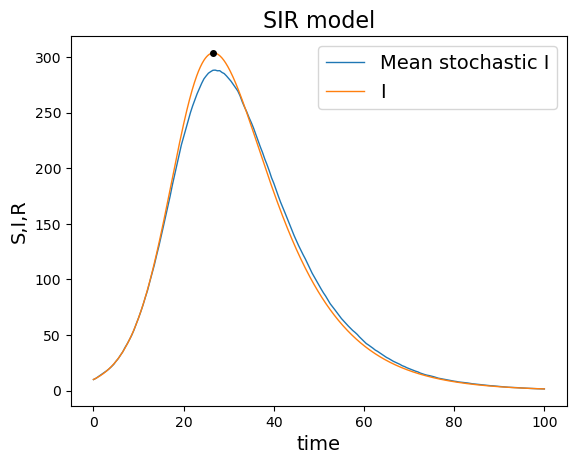

In [8]:
# Plot of IVals average:
# import libraries
import numpy as np 
import matplotlib.pyplot as plt


# Parameter values
beta = 3.0*10**-4
mu = 0.1

# Function which runs one stochastic simulation
def SingleStochasticSIRSimulation ():
    # Set up arrays to record event times, and values of S, I and R after after each event
    SVec = np.array([])
    IVec = np.array([])
    RVec = np.array([])
    tVec = np.array([])

    # Set up an array to record pre-determined times and values of I at those times
    tVals = np.array([i*0.5 for i in range(201)])
    IVals = np.array([0 for i in range(201)])

    # Set initial conditions and the initial time
    S = 10**3 - 10
    I = 10
    R = 0
    t = 0

    IVals[0] = I

    # Record initial conditions in the S, I, R and t arrays
    SVec = np.append(SVec, S)
    IVec = np.append(IVec, I)
    RVec = np.append(RVec, R)
    tVec = np.append(tVec, t)

    # While the outbreak is ongoing (I > 0), generate events
  
    while I > 0:
    
        previous_time = t
    
        r1 = np.random.uniform(0, 1, 1)
        totalRate = beta*I*S + mu*I
        t = t - (1/totalRate)*np.log(r1)
    
        new_time = t
    
        for i in range(201):
            if previous_time <= tVals[i] < new_time:
                IVals[i] = I
    
        r2 = np.random.uniform(0, 1, 1)
        if r2 < (beta*I*S)/totalRate:
            S = S - 1
            I = I + 1
        else:
            I = I - 1
            R = R + 1
        
        SVec = np.append(SVec, S)
        IVec = np.append(IVec, I)
        RVec = np.append(RVec, R)
        tVec = np.append(tVec, t)

    return IVals

newtVals = np.array([i*0.5 for i in range(201)])
Matrix_for_IVals = np.zeros((100,201))
for i in range(100):
    Matrix_for_IVals[i,:] = SingleStochasticSIRSimulation()
mean_IVals = np.mean(Matrix_for_IVals, axis=0)
plt.plot(newtVals, mean_IVals, lw=1, label="Mean stochastic I")
plt.xlabel("time")
plt.ylabel("I")
plt.legend()

from scipy.integrate import odeint

#Let the function take four arguments
def SIR(y, t, beta, mu):
    S, I, R=y

    N = S + I + R
    Sdot = -beta * S * I
    Idot = beta * S * I - mu * I
    Rdot = mu * I
    
    return Sdot, Idot, Rdot
#Set up time grid for the solution
tf = 100
# Very small timesteps for a more refined model
Nsteps = 1000
t = np.linspace(0, tf, Nsteps+1)

#Now define them and set initial conditions
S0 = 10**3 - 10
I0 = 10
R0 = 0
y0 = np.array([S0, I0, R0])

#Initiate the numerical solution
y_sol = odeint(SIR, y0, t, args=(beta,mu))

S = y_sol[:,0]
I = y_sol[:,1]
R = y_sol[:,2]

#Find the max value of I
index_of_max = np.argmax(I)
max_I_value = I[index_of_max]

#Plot the mean stochastic I values and deterministic I values on same axes without S and R
#plt.plot(t, S, label = "S")
plt.plot(t, I, lw = 1, label = "I")
#plt.plot(t, R, label = "R")
plt.xlabel("time", fontsize = 14)
plt.ylabel("S,I,R", fontsize = 14)
plt.title("SIR model", fontsize = 16)
plt.legend(fontsize = 14)
plt.plot(t[index_of_max], max_I_value,'ko', markersize = 4, label='Max I') #labeling I
plt.show()

## Task A5. The probability of a major outbreak (worth approximately 12% of the marks)

**Assignment:** Run 1000 simulations of the stochastic SIR model, starting from a single infected individual (with the remainder of the population susceptible). Count the number of simulations in which the final value of $I+R$ exceeds 10 (i.e. the number for which $R>10$ when $I$ hits zero), and compare this to the analytic estimate for the "probability of a major outbreak" described in the Lecture.

Details: 
- Use the following parameter values for the baseline case (where time is again measured in days): $\beta = 3 \times 10^{-4}$, $\mu = 0.1$, $N = 10^{3}$.
- Recall from the lecture that the analytic estimate for the probability of a major outbreak is $p = 1 - \frac{1}{R_0}$, where $R_0 = \frac{\beta N}{\mu}$.
- Run 1000 simulations of the stochastic SIR model. Calculate (and print) the proportion of simulations in which the final value of $I+R$ exceeds 10.
- Calculate and print the analogous analytic estimate for the probability of a major outbreak.

- Hint: To run 1000 simulations of the stochastic SIR model, you will need to use a FOR loop. To run the simulations more quickly, you do not have to store the values of $t$, $S$, $I$ and $R$ after every event (instead, simply store the value of $I + R$ at the end of the simulation).

*Insert code and markdown cells below, as appropriate, in which to provide your response to this task.*

---

### Task A5: The Probability of a Major Outbreak

In this task, we use the stochastic SIR model to estimate the probability of a major outbreak. Starting from a single infected individual, we run a large number of simulations to capture the inherent randomness in how an epidemic may evolve.

For each simulation, we record the final number of removed individuals and classify the outcome as a “major outbreak” if this number exceeds a specified threshold. By computing the proportion of simulations that result in a major outbreak, we obtain a numerical estimate of this probability.

We then compare this simulation-based estimate with the corresponding analytic approximation derived in the lectures. This allows us to assess how well the theoretical prediction matches the behaviour observed in stochastic simulations.

In [9]:
import numpy as np
## Parameters
beta = 3.0 * 10**-4
mu = 0.1
N = 10**3


# Calculate R0 and the analytic probability of a major outbreak
R0 = (beta * N) / mu
analytic_p = 1 - (1 / R0)

print(f"Analytic estimate for probability: {analytic_p:.4f}")

# Simulation setup
n_sims = 1000
major_outbreak_count = 0

# Run 1000 simulations
for i in range(n_sims):
    # Initial conditions: single infected individual
    S = N - 1
    I = 1
    R = 0
    
    # Stochastic loop: continues while there are infected individuals
    while I > 0:
        # Calculate rates for the two possible events
        rate_infect = beta * S * I
        rate_recover = mu * I
        total_rate = rate_infect + rate_recover
        
        # Determine which event happens next based on relative probabilities
        r = np.random.uniform(0, 1)
        if r < (rate_infect / total_rate):
            S -= 1
            I += 1
        else:
            I -= 1
            R += 1
            
    # Check if run results in major outbreak (I+R > 10)
    # Since I=0 at end, check if R > 10
    if R > 10:
        major_outbreak_count += 1

## Results
simulated_p = major_outbreak_count / n_sims
print(f"Simulated proportion of major outbreaks: {simulated_p:.4f}")


Analytic estimate for probability: 0.6667
Simulated proportion of major outbreaks: 0.6430


## Section B (worth approximately 40% of the marks)

## Task B1. Extensions
**Assignment:** Using Python, write code to complete the following exercises:

- Consider the variable $M$, which represents the total number of individuals ever infected over the entire course of a simulation of the stochastic SIR model (run until $I$ hits zero) - i.e. the final value of $I + R$. Plot a graph of ${\rm Prob}(M > m)$ as a function of $m$, for the default parameter values described in Task A5 above (compute the probability by running a large number of stochastic simulations and calculating the proportion of simulations in which $M>m$). Hint: You only have to run the simulations once (rather than running multiple simulations for each value of $m$).
- Add a vertical line to the plot marking the value of $m$ that corresponds to the (positive) solution to the "final size equation" described in the Lecture (note: you will have to look up an appropriate Python function to solve this equation numerically, as in Task A2 above).
- Now instead consider the stochastic SIS model described in the paper "Will an outbreak exceed available resources for control? Estimating the risk from invading pathogens using practical definitions of a severe epidemic" by Thompson, Gilligan and Cunniffe (https://royalsocietypublishing.org/doi/epdf/10.1098/rsif.2020.0690). The key difference between the stochastic SIR model and the stochastic SIS model is that, in the stochastic SIS model, individuals go back into the $S$ compartment when they recover (rather than entering the $R$ compartment). Pick either the "Final size" or "Duration" definition of a severe epidemic described in that paper, and write code to reproduce the relevant figure from that article using model simulations (either Fig 4a or Fig 4b; n.b. you are only required to reproduce the solid lines in the chosen figure). Hint: You do not have to simulate the model until $I$ hits zero to make this figure - that might take a very long time. Instead, you can stop each simulation as soon as the relevant maximum value on the x-axis is exceeded (or when $I$ hits zero, if that occurs first).
- Most of this Assignment involved using deterministic and stochastic versions of the basic SIR model. However, the SIR model is quite simple and does not include some important features that affect transmission of pathogens in the real world. Do some research into ways that the SIR model can be extended to include additional real-world realism. Write one or two paragraphs to summarise your findings (including noting some pathogens/diseases for which the extensions that you explain are appropriate).

*Insert code and markdown cells below, as appropriate, in which to provide your response to this task.*


---

## Task B1 Part 1: Distribution of Total Infected

In this task, we examine the distribution of the total number of individuals infected over the course of an epidemic in the stochastic SIR model. This quantity corresponds to the final value of the removed population once the number of infected individuals reaches zero.

We run a large number of stochastic simulations and, for each simulation, record the total number of individuals infected. Using these results, we estimate the probability that the total number of infections exceeds a given threshold.

Finally, we plot this probability as a function of the threshold value, providing insight into how likely different outbreak sizes are under the default parameter values.

In [10]:
import numpy as np
## Parameters
beta = 3.0 * 10**-4
mu = 0.1
N = 10**3


# Calculate R0 and the analytic probability of a major outbreak
R0 = (beta * N) / mu
analytic_p = 1 - (1 / R0)

print(f"Analytic estimate for probability: {analytic_p:.4f}")

# Simulation setup
n_sims = 1000
major_outbreak_count = 0

# Run 1000 simulations
for i in range(n_sims):
    # Initial conditions: single infected individual
    S = N - 1
    I = 1
    R = 0
    
    # Stochastic loop: continues while there are infected individuals
    while I > 0:
        # Calculate rates for the two possible events
        rate_infect = beta * S * I
        rate_recover = mu * I
        total_rate = rate_infect + rate_recover
        
        # Determine which event happens next based on relative probabilities
        r = np.random.uniform(0, 1)
        if r < (rate_infect / total_rate):
            S -= 1
            I += 1
        else:
            I -= 1
            R += 1
            
    # Check if run results in major outbreak (I+R > 10)
    # Since I=0 at end, check if R > 10
    if R > 10:
        major_outbreak_count += 1

## Results
simulated_p = major_outbreak_count / n_sims
print(f"Simulated proportion of major outbreaks: {simulated_p:.4f}")


Analytic estimate for probability: 0.6667
Simulated proportion of major outbreaks: 0.6750


Analytic estimate for probability of major outbreak: 0.6667


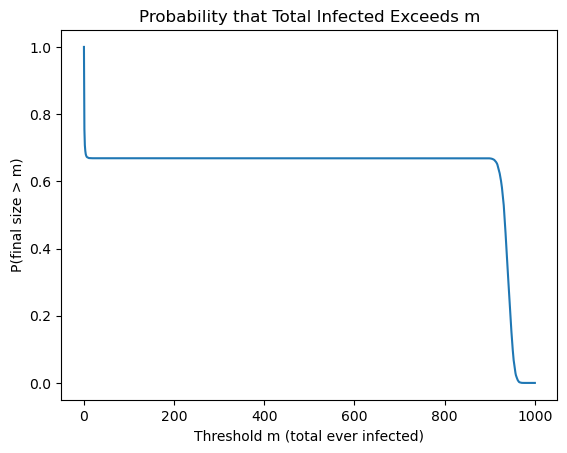

In [11]:
import numpy as np
import matplotlib.pyplot as plt

## Parameters
beta = 3.0 * 10**-4
mu = 0.1
N = 10**3

# Calculate R0 and analytic probability
R0 = (beta * N) / mu
analytic_p = 1 - (1 / R0)

print(f"Analytic estimate for probability of major outbreak: {analytic_p:.4f}")

# Simulation setup
n_sims = 10000
FinalRVals = []

# Outer loop iterates through simulations
for i in range(n_sims):
    
    S = N - 1
    I = 1
    R = 0
    
    # Inner loop runs stochastic simulation until infection dies out
    while I > 0:
        rate_infect = beta * S * I
        rate_recover = mu * I
        total_rate = rate_infect + rate_recover
        
        r = np.random.uniform(0, 1)
        
        if r < (rate_infect / total_rate):
            S -= 1
            I += 1
        else:
            I -= 1
            R += 1
    
    # Store total ever infected (final epidemic size)
    FinalRVals.append(R)

FinalRVals = np.array(FinalRVals)

# Define threshold values k
m_values = np.arange(0, N+1, 1)

# Compute probability P(final size > k)
probabilities = [(FinalRVals > m).mean() for m in m_values]

# Plot result
plt.figure()
plt.plot(m_values, probabilities)
plt.xlabel("Threshold m (total ever infected)")
plt.ylabel("P(final size > m)")
plt.title("Probability that Total Infected Exceeds m")
plt.show()

## Task B1 Part 2: Comparison with the Final Size Equation

In this task, we enhance the previous analysis by comparing the stochastic simulation results with the theoretical prediction given by the final size equation. 

After computing the numerical solution of the final size equation, we add a vertical line to the existing plot at the corresponding value. This allows us to visually assess how well the theoretical final epidemic size aligns with the distribution of outcomes obtained from the stochastic simulations.

Analytic estimate for probability of major outbreak: 0.6667
Final size equation solution R_inf = 940.48


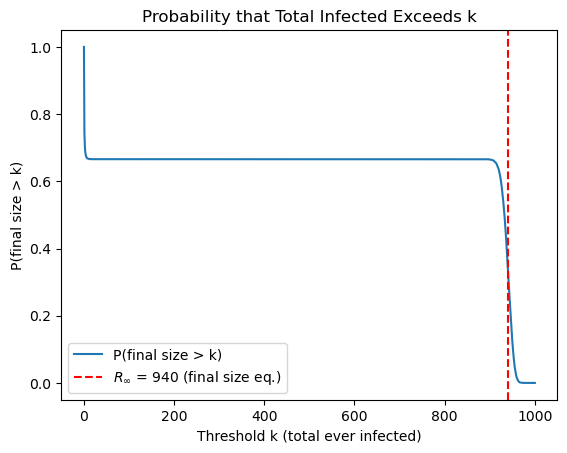

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

## Parameters
beta = 3.0 * 10**-4
mu = 0.1
N = 10**3

# Calculate R0 and analytic probability
R0 = (beta * N) / mu
analytic_p = 1 - (1 / R0)
print(f"Analytic estimate for probability of major outbreak: {analytic_p:.4f}")

# --- Solve Final Size Equation numerically ---
# R_inf = N - N * exp(-beta * R_inf / mu)
# Rearranged to f(R_inf) = 0:
def final_size_eq(R_inf):
        return R_inf - N + N * np.exp(-beta * R_inf / mu)

# Use fsolve with a large initial guess to find the positive (major outbreak) solution
R_inf_solution = fsolve(final_size_eq, x0=0.9 * N)[0]
print(f"Final size equation solution R_inf = {R_inf_solution:.2f}")

# Simulation setup
n_sims = 10000
FinalRVals = []

# Run simulations
for i in range(n_sims):
    S = N - 1
    I = 1
    R = 0
    
    while I > 0:
        rate_infect = beta * S * I
        rate_recover = mu * I
        total_rate = rate_infect + rate_recover
        
        r = np.random.uniform(0, 1)
        
        if r < (rate_infect / total_rate):
            S -= 1
            I += 1
        else:
            I -= 1
            R += 1
    
    FinalRVals.append(R)

FinalRVals = np.array(FinalRVals)

# Define threshold values k
m_values = np.arange(0, N+1, 1)

# Compute probability P(final size > k)
probabilities = [(FinalRVals > m).mean() for m in m_values]

# Plot result
plt.figure()
plt.plot(m_values, probabilities, label="P(final size > k)")
plt.axvline(x=R_inf_solution, color='red', linestyle='--', 
            label=f"$R_\\infty$ = {R_inf_solution:.0f} (final size eq.)")
plt.xlabel("Threshold k (total ever infected)")
plt.ylabel("P(final size > k)")
plt.title("Probability that Total Infected Exceeds k")
plt.legend()
plt.show()


## Task B1 Part 3: Stochastic SIS Model and Severe Epidemics

In this task, we extend our analysis to the stochastic SIS (Susceptible–Infected–Susceptible) model, in which individuals return to the susceptible compartment after recovery rather than becoming permanently removed. This leads to fundamentally different epidemic dynamics, as reinfection is possible.

Using the framework described in the paper by Thompson, Gilligan, and Cunniffe, we investigate the concept of a “severe epidemic” under the *duration* definition. We implement stochastic simulations of the SIS model and use these to estimate the probability of a severe epidemic under the chosen definition.

Our goal is to reproduce one of the key figures from the paper (Fig. 4b), focusing on the solid curves. To improve computational efficiency, each simulation is terminated early if the relevant threshold on the x-axis is exceeded, or if the infection dies out. This allows us to efficiently approximate the behaviour shown in the original study.

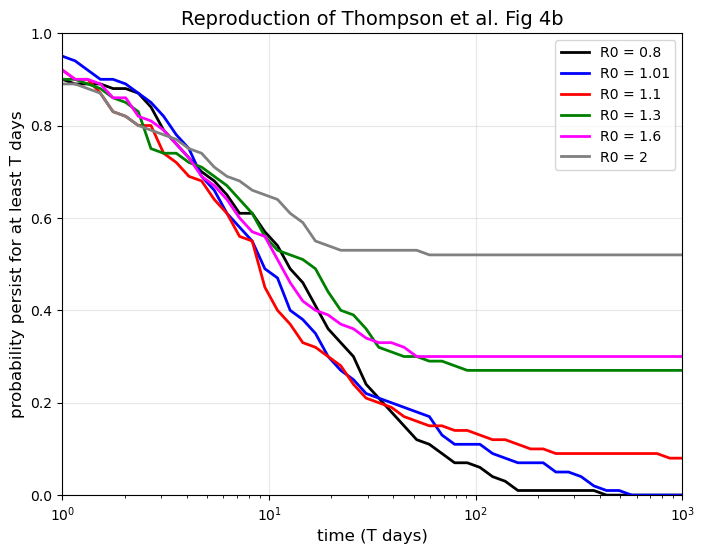

In [13]:
# Key point is that recovered individuals return back into the susceptible pool
# Chosen the "Duration" definition of severe pandemic 
import numpy as np
import matplotlib.pyplot as plt

# Parameters matching Fig 4b
N = 1000
I0 = 1
mu = 0.1
R0_values = [0.8, 1.01, 1.1, 1.3, 1.6, 2]
colors = ['black', 'blue', 'red', 'green', 'magenta', 'gray'] 
T_max = 1000 
n_simulations = 100  # quicker run-time
T_thresholds = np.logspace(0, np.log10(T_max), 50) # logarithmic spacing

plt.figure(figsize=(8, 6))

# Simulation loop
for R0, color in zip(R0_values, colors):

    beta_scaled = (R0 * mu) / N
    durations = []

    for i in range(n_simulations):

        I = I0
        t = 0

        while I > 0 and t < T_max:

            S = N - I

            rate_infect = beta_scaled * S * I
            rate_recover = mu * I
            total_rate = rate_infect + rate_recover

            dt = -np.log(np.random.random()) / total_rate
            t += dt

            if np.random.random() < rate_infect / total_rate:
                I += 1
            else:
                I -= 1

        durations.append(t)

    # Calculate P(Duration > T)
    prob_exceeds = [np.sum(np.array(durations) >= T) / n_simulations for T in T_thresholds]
    
    plt.plot(T_thresholds, prob_exceeds, color=color, lw=2, label=f'R0 = {R0}')

# Plotting formatted to match Fig 4b
plt.xscale('log') # logarithmic x-axis
plt.xlabel("time (T days)", fontsize=12)
plt.ylabel("probability persist for at least T days", fontsize=12)
plt.title("Reproduction of Thompson et al. Fig 4b", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 1)
plt.xlim(1, T_max)
plt.show()


## Task B1 Part 4: Extensions of the SIR Model
In our research to extend the SIR model, we incorporated several real-world factors, including **latent periods** and **isolation measures**. By introducing an **Exposed (E)** population representing individuals who are infected but not yet infectious, we can more accurately reflect the **time lag** between initial infection and infectiousness, leading to the **SEIR model**. Similarly, we extended the model by accounting for infected individuals who were hospitalized and hence isolated. This is represented by a **Quarantined (Q)** population, which effectively removes them from the infectious pool (the **SEIQR model**). These extensions are vital for modeling pathogens like **COVID-19**.

Additionally, we integrated **vital dynamics** (birth and death rates) to simulate long-term epidemics. In this scenario, we assume constant birth and death rates to maintain a stable total population, a model that is particularly useful for childhood diseases such as **chickenpox**. Beyond these, we investigated the **SIS model**, a special case where no permanent recovery (R) exists. In this model, individuals return directly to the **Susceptible (S)** state after recovery, accurately simulating recurring infections like the **common cold**. These extensions demonstrate the transition from a basic theoretical framework to a more comprehensive tool to capture main features of an epidemiology. However, reality is still far more complicated and requires a lot more understanding.

## Notes about this submission

You will submit a single Jupyter notebook for this project assignment (this notebook, with your additions).

- The last thing you should do before submitting the notebook is to Restart Kernel and Run All Cells. You should then save the notebook and submit the .ipynb file. **You will lose marks if you submit a notebook that has not been run.**

- You are expected to add code and markdown cells to this document as appropriate to provide your responses to the tasks. However, throughout this assignment, please do use the deterministic and stochastic SIR model codes from the Epidemiology I and Epidemiology II code notebooks as required (i.e., you are supposed to copy that code across and adapt it, rather than start coding from scratch).

- This assignment lends itself to producing a nice document. A good guide for what the final notebook should be like is: if the notebook is run and all code cells and task descriptions are collapsed, the notebook should be readable as a short report, primarily consisting of a short introduction to each section followed by figures and descriptions of the figures.

- Use the comments in the "Epidemiology I code" notebook as a guide to the level of code commenting expected. Each code cell should begin with a comment line or lines concisely stating what the cell is for (alternatively, precede the code cell with a markdown cell explaining what you are about to do). Functions should have comments describing what they do. It can be assumed that the reader understands Python to a basic level (e.g. comments like "Create an array" or "Make a plot" on every line are unnecessary). Add comments to set off blocks of code or to note anything tricky.

---